# 🚨 Notebook 06.3: DBSCAN Deep Dive
## Objective
In K-Means (Notebook 06.2), the algorithm was forced to put every single property into a bucket. This caused the massive rural farms to heavily skew the data.

Here, we use **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**. DBSCAN does not force properties into buckets. Instead, it natively identifies dense groupings of standard houses and automatically isolates structural anomalies (like rural farms) as 'Noise' (Label: `-1`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

### 1. Load Preprocessed Data
*(Note: This dataset includes the extreme farm properties, so we can test if DBSCAN natively catches them.)*

In [2]:
X_scaled = pd.read_csv('../../data/processed/X_cluster_scaled.csv')
X_raw = pd.read_csv('../../data/processed/X_cluster_raw.csv')
y_price = pd.read_csv('../../data/processed/y_cluster_price.csv')
X_raw['SalePrice'] = y_price.squeeze()


### 2. Hyperparameter Tuning (K-Distance Graph)
To find the optimal `eps` (radius) for DBSCAN, we calculate the distance to the 5th nearest neighbor for every property. We look for the 'knee' in the curve to determine the maximum distance before a house is considered an anomaly.

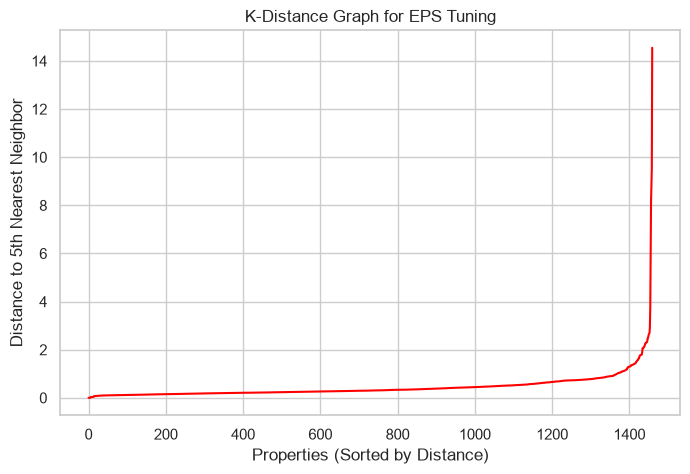

In [3]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4], axis=0)
plt.figure(figsize=(8, 5))
plt.plot(distances, color='red')
plt.title('K-Distance Graph for EPS Tuning')
plt.ylabel('Distance to 5th Nearest Neighbor')
plt.xlabel('Properties (Sorted by Distance)')
plt.grid(True)
plt.show()

### 3. Fit DBSCAN Model
Based on the 'knee' in the graph above, we set our radius to `eps=1.5`.

In [4]:
dbscan = DBSCAN(eps=1.5, min_samples=10)
X_raw['DBSCAN_Label'] = dbscan.fit_predict(X_scaled)

### 4. Anomaly Analysis
Let's see how many extreme structural anomalies DBSCAN found in Ames, Iowa, and compare their averages to the normal housing market.

In [5]:
anomaly_counts = X_raw['DBSCAN_Label'].value_counts().rename(index={0: 'Normal Houses', -1: 'Extreme Anomalies'})
display(anomaly_counts.to_frame('Count'))

analysis = X_raw.groupby('DBSCAN_Label').mean().round(1)
analysis.index = ['Extreme Anomalies', 'Normal Houses']
display(analysis.sort_values('LotArea', ascending=False))

,Count
DBSCAN_Label,
Normal Houses,1429
Extreme Anomalies,31


,TotalSF,OverallQual,YearBuilt,LotArea,GarageCars,SalePrice
Extreme Anomalies,4265.2,6.9,1953.3,47672.5,2.5,302683.2
Normal Houses,2530.2,6.1,1971.7,9710.8,1.8,178279.8


### 5. Visualization of Outliers
We will plot the Size vs Lot Area of the houses. Notice how DBSCAN completely ignores the standard suburban cluster (grey) and mathematically isolates the massive farms and mega-mansions (red).

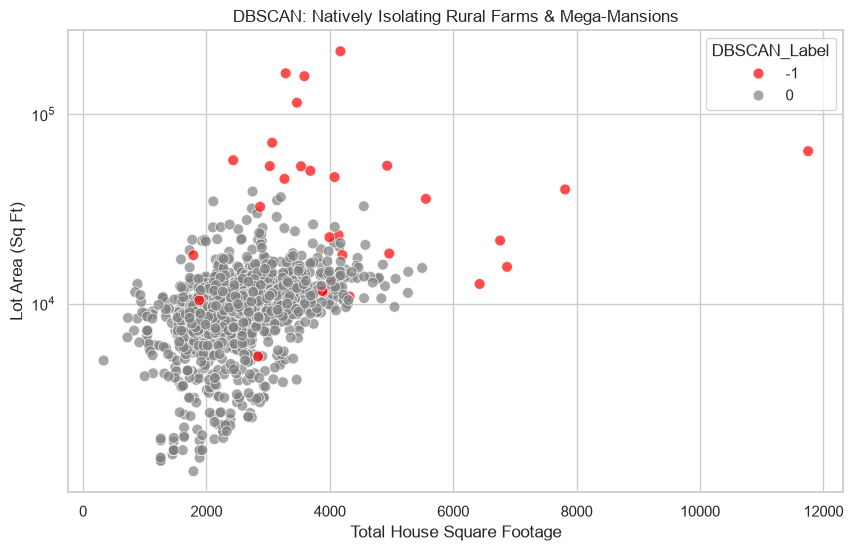

In [6]:
plt.figure(figsize=(10, 6))
palette = {-1: 'red', 0: 'grey'}
sns.scatterplot(data=X_raw, x='TotalSF', y='LotArea', hue='DBSCAN_Label', palette=palette, alpha=0.7, s=60)
plt.title('DBSCAN: Natively Isolating Rural Farms & Mega-Mansions')
plt.ylabel('Lot Area (Sq Ft)')
plt.xlabel('Total House Square Footage')
plt.yscale('log') # Log scale to clearly see the massive acreage differences
plt.show()

### 6. Pipeline Export (Removing the Noise)
Now that DBSCAN has mathematically identified the anomalies without us having to hardcode any rules (like `LotArea > 100,000`), we will filter out the `-1` labels. We will export this perfectly clean dataset to be used in our final Hierarchical Clustering model.

In [7]:
# Filter out the anomalies
X_clean_raw = X_raw[X_raw['DBSCAN_Label'] != -1].drop(columns=['DBSCAN_Label'])
X_clean_scaled = X_scaled.loc[X_clean_raw.index]
y_clean_price = y_price.loc[X_clean_raw.index]

# Export the clean data
X_clean_raw.to_csv('../../data/processed/X_cluster_clean_raw.csv', index=False)
X_clean_scaled.to_csv('../../data/processed/X_cluster_clean_scaled.csv', index=False)
y_clean_price.to_csv('../../data/processed/y_cluster_clean_price.csv', index=False)

print(f"Original properties: {len(X_raw)}")
print(f"Cleaned properties passed to next phase: {len(X_clean_raw)}")

Original properties: 1460
Cleaned properties passed to next phase: 1429
